# 07c · Protocol P and stress folds (phase 7c)
Comparability and stress evidence only. Frozen configuration, no retuning (D94). Batch-3 labels are spent (D97): descriptive scoring only, nothing is selected on these numbers. Writes only inside `outputs/phase7c`.

## S0 · Setup

In [1]:
# S0 · setup, environment, hash guards, log "start"
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import sys
sys.dont_write_bytecode = True
import json, hashlib, time, platform, warnings, re, inspect, subprocess, importlib, datetime as dt, textwrap, ctypes, atexit
from pathlib import Path

SMOKE = False   # True = smoke run: 8 cells per set, E=2, 200 bootstrap draws, outputs/phase7c/smoke; never quote smoke results
T0 = time.time()

def _need(mod, pkg=None):
    try:
        importlib.import_module(mod)
    except ImportError:
        r = subprocess.run(["uv", "pip", "install", pkg or mod], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f"uv pip install {pkg or mod} failed: {r.stderr[-400:]}")
        importlib.invalidate_caches()
        importlib.import_module(mod)
for _m, _p in [("numpy", None), ("pandas", None), ("pyarrow", None), ("scipy", None), ("sklearn", "scikit-learn"), ("matplotlib", None), ("torch", None)]:
    _need(_m, _p)
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

KEEP_AWAKE = os.name == "nt"
def keep_awake(on):
    if KEEP_AWAKE:
        ctypes.windll.kernel32.SetThreadExecutionState(0x80000001 if on else 0x80000000)
keep_awake(True)
atexit.register(keep_awake, False)

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "notebooks").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise RuntimeError(f"project root not found: no folder in {_cwd} or its parents contains both notebooks/ and data/")
OUT = ROOT / "outputs" / "phase7c" / ("smoke" if SMOKE else "")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = OUT / "cache"
PRED_PATH = OUT / "phase7c_predictions.parquet"
LOG_PATH = OUT / "phase7c_log.jsonl"
REPORT_PATH = OUT / "phase7c_report.txt"
VER_PATH = OUT / "verification_report.json"

def W(path):
    p = Path(path).resolve()
    if OUT.resolve() not in p.parents:
        raise PermissionError(f"write refused (outside {OUT}): {p}")
    p.parent.mkdir(parents=True, exist_ok=True)
    return p
def _jd(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return sorted(o) if isinstance(o, set) else list(o)
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o))
def write_text(path, text): W(path).write_text(text, encoding="utf-8", newline="\n")
def write_json(path, obj): write_text(path, json.dumps(obj, indent=2, sort_keys=True, default=_jd) + "\n")
def sha256_bytes(b): return hashlib.sha256(b).hexdigest()
def sha256_file(p, lf=False):
    b = Path(p).read_bytes()
    return sha256_bytes(b.replace(b"\r\n", b"\n") if lf else b)
def now_utc(): return dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")

REPORT = []
def emit(text=""):
    print(text); REPORT.append(str(text))
def show(title, df, nd=3):
    emit(title); emit("-" * len(title))
    emit(df.to_string(index=False, float_format=lambda v: f"{v:.{nd}f}")); emit("")

CHECKS, EXTRA = [], {}
class CheckFail(RuntimeError): pass
def report_text(extra_tail=()):
    L = ["PHASE 7c - PROTOCOL P AND STRESS FOLDS" + (" [SMOKE RUN: do not quote]" if SMOKE else ""), "=" * 78, ""] + REPORT
    L += ["CHECKS", "-" * 78] + [f"[{c['status']}] {c['name']}" + (f" - {c['detail']}" if c["detail"] else "") for c in CHECKS] + [""] + list(extra_tail)
    return "\n".join(L) + "\n"
def dump_report(failed=None):
    rep = dict(created_utc=now_utc(), smoke=SMOKE, failed=failed, checks=CHECKS, extra=EXTRA, elapsed_s=round(time.time() - T0, 1))
    write_json(VER_PATH, rep)
    write_text(REPORT_PATH, report_text())
    n = {k: sum(c["status"] == k for c in CHECKS) for k in ("PASS", "WARN", "FAIL")}
    print("REPORT DUMPED:", n)
def check(name, ok, detail="", warn_only=False):
    status = "PASS" if ok else ("WARN" if warn_only else "FAIL")
    CHECKS.append(dict(name=name, status=status, detail=str(detail)))
    print(f"[{status}] {name}" + (f" - {detail}" if str(detail) else ""))
    if status == "FAIL":
        dump_report(failed=name)
        raise CheckFail(f"{name}: {detail}")

# ---- environment: GPU if available (WARN otherwise), fp32, TF32 off, deterministic
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.set_float32_matmul_precision("highest")
torch.use_deterministic_algorithms(True, warn_only=True)
_cuda = torch.cuda.is_available()
DEVICE = torch.device("cuda" if _cuda else "cpu")
check("CUDA available (else CPU fallback)", _cuda, f"torch.cuda.is_available() = {_cuda}; training on {DEVICE}", warn_only=True)
if _cuda:
    _free, _total = torch.cuda.mem_get_info()
    _name = torch.cuda.get_device_name(0)
else:
    _free = _total = 0; _name = "cpu"
emit(f"torch {torch.__version__} | CUDA available {_cuda} | device {_name} | free VRAM {_free / 2**30:.2f} GB of {_total / 2**30:.2f} GB | python {platform.python_version()}")
check("TF32 off, deterministic, fp32", not torch.backends.cuda.matmul.allow_tf32 and not torch.backends.cudnn.allow_tf32 and torch.backends.cudnn.deterministic,
      f"matmul_tf32={torch.backends.cuda.matmul.allow_tf32}, cudnn_tf32={torch.backends.cudnn.allow_tf32}, deterministic={torch.backends.cudnn.deterministic}")
check("torch version is 2.14.1+cu130", torch.__version__ == "2.14.1+cu130", f"torch {torch.__version__}", warn_only=True)
emit(f"ROOT {ROOT} | OUT {OUT} | SMOKE {SMOKE}")

# ---- append-only hash-chained log
def log_entries():
    if not LOG_PATH.exists(): return []
    return [json.loads(l) for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
def log_append(event, **kw):
    prev = ""
    if LOG_PATH.exists():
        lines = [l for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
        prev = sha256_bytes(lines[-1].encode("utf-8")) if lines else ""
    entry = dict(t_utc=now_utc(), event=event, prev_line_sha256=prev, **kw)
    with open(W(LOG_PATH), "a", encoding="utf-8", newline="\n") as f:
        f.write(json.dumps(entry, sort_keys=True, default=_jd) + "\n")
    return entry
def log_has(event): return any(e["event"] == event for e in log_entries())
def verify_chain():
    lines = [l for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
    prev, bad = "", []
    for i, l in enumerate(lines):
        if json.loads(l)["prev_line_sha256"] != prev: bad.append(i)
        prev = sha256_bytes(l.encode("utf-8"))
    return len(lines), bad

# ---- SHA-256 guards (read-only inputs)
GUARDS = {
    "frozen_config": ("outputs/phase6b/frozen_config.json", "78b571c7526551c70a01cb709661052ddfb5b4c9783e4eb5babb1c7e11b65fe5"),
    "soh_deep_v4": ("src/soh_deep_v4.py", "2be9ce5ded197b16028079e7d34b550c683f4152b528f55f5064251b146eded4"),
    "soh_deep_v3": ("src/soh_deep_v3.py", "9c022dd391193de9c65f2d77b9dcdc5a2e939419596ecb38a55399ffcc06cbbb"),
    "preregistration": ("outputs/phase7a/preregistration.json", "11f9741387cb001ef55aa8459e4857ab70871e89cd03e7cce318043be41c8bce"),
    "batch3_verdict": ("outputs/phase7a/batch3_verdict.json", "57a054bdf25243d3b9e0aced2c0c245135da2c769b2d1e635d329b742fc4deb8"),
    "monitor_config": ("outputs/phase7b/monitor_config.json", "638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2"),
    "monitor_config_addendum": (None, "d842e5f4c3186889ce8292e0654e1a0ca29d4434bcdeaf1bd3c7131479479632"),
}
GUARD_PATH = {}
for _k, (_rel, _h) in GUARDS.items():
    if _rel is None:
        _hits = sorted((ROOT / "outputs").rglob("monitor_config_addendum.json"))
        check("monitor_config_addendum.json located", len(_hits) == 1, f"{len(_hits)} match(es): {[str(h.relative_to(ROOT)) for h in _hits]}")
        GUARD_PATH[_k] = _hits[0]
    else:
        GUARD_PATH[_k] = ROOT / _rel
def verify_frozen(tag):
    res = {}
    for k, (_rel, h) in GUARDS.items():
        p = GUARD_PATH[k]
        raw = sha256_file(p) if p.exists() else None
        lf = sha256_file(p, True) if (p.exists() and p.suffix == ".py") else raw
        ok = h in (raw, lf)
        res[k] = dict(path=str(p.relative_to(ROOT)), expected=h, got=raw, got_lf=lf, ok=ok)
        check(f"[{tag}] sha256 {k}", ok, f"{p.name}: expected {h[:16]}..., got {str(raw)[:16]}...")
    return res
HASHES_START = verify_frozen("start")

# ---- frozen configuration (read, never edited)
EXPECTED_CFG = dict(
    common=dict(E=120, batch=256, seeds=[42, 43, 44, 45, 46], stride=5, head="abs", huber_delta_pp=1.0, noise_sigma=0.02, clip=1.0,
                warmup_frac=0.05, nominal_ah=1.1, trees=300, tree_max_features=0.33, tree_seed=42),
    windows=dict(W300=dict(lr=0.004, wd=0.0001, b4r_leaf=3), W240=dict(lr=0.008, wd=0.001, b4r_leaf=1)))
FCFG = json.loads(GUARD_PATH["frozen_config"].read_text(encoding="utf-8"))
def _sub_eq(exp, got):
    if isinstance(exp, dict):
        return isinstance(got, dict) and all(k in got and _sub_eq(v, got[k]) for k, v in exp.items())
    return exp == got
check("frozen_config.json content equals the expected values", _sub_eq(EXPECTED_CFG, FCFG), f"file keys: {list(FCFG)}")
COM, WINDOWS = FCFG["common"], ["W300", "W240"]
GRID_V = {"W300": 3.00, "W240": 2.40}
E_RUN = 2 if SMOKE else COM["E"]
DRAWS = 200 if SMOKE else 5000
FORMAL_PATH = ROOT / "outputs/phase7a/formal_comparators.json"
FORMAL = json.loads(FORMAL_PATH.read_text(encoding="utf-8"))
check("formal B4 leaf is 5 for both windows (7a formal_comparators.json)", all(FORMAL[w]["B4_leaf"] == 5 for w in WINDOWS),
      {w: FORMAL[w]["B4_leaf"] for w in WINDOWS})
B4_LEAF = {w: 5 for w in WINDOWS}
B4R_LEAF = {w: FCFG["windows"][w]["b4r_leaf"] for w in WINDOWS}
emit(f"frozen config: E={COM['E']} (run with E={E_RUN}), seeds {COM['seeds']}, windows " + json.dumps({w: FCFG['windows'][w] for w in WINDOWS}) + f", B4 leaf {B4_LEAF}, B4r leaf {B4R_LEAF}")

# ---- expectations, written BEFORE any prediction or score exists (hash goes into the "start" log entry)
EXPECT = [
    dict(id="H8", text="Every model's error on b1->b2 and on b2->b1 is larger than its Protocol D error (life-range extrapolation)."),
    dict(id="H9", text="M0+idx is worse than M0 on at least one stress fold at W300."),
    dict(id="H10", text="On the Protocol P primary test, cells with a policy twin have lower M0 MAE than cells without, at least at one window."),
    dict(id="H11", text="Protocol P primary-test M0 MAE at W240 is within a factor 1.6 of the Protocol D value (41 vs about 70 training cells)."),
]
EXP_SHA = sha256_bytes(json.dumps(EXPECT, sort_keys=True).encode("utf-8"))
log_append("start", smoke=SMOKE, notebook="notebooks/07c_protocolP_stress_folds.ipynb", decision="D94 frozen configuration, no retuning; D97 batch-3 labels spent",
           guards={k: v["expected"] for k, v in HASHES_START.items()}, expectations_sha256=EXP_SHA, torch=torch.__version__, device=_name)
emit(f"expectations H8-H11 registered, sha256 {EXP_SHA}")


[PASS] CUDA available (else CPU fallback) - torch.cuda.is_available() = True; training on cuda
torch 2.14.1+cu130 | CUDA available True | device NVIDIA GeForce RTX 3050 6GB Laptop GPU | free VRAM 5.04 GB of 6.00 GB | python 3.13.13
[PASS] TF32 off, deterministic, fp32 - matmul_tf32=False, cudnn_tf32=False, deterministic=True
[PASS] torch version is 2.14.1+cu130 - torch 2.14.1+cu130
ROOT C:\workstation\3RD YEAR\Battery-Health-Estimation | OUT C:\workstation\3RD YEAR\Battery-Health-Estimation\outputs\phase7c | SMOKE False
[PASS] monitor_config_addendum.json located - 1 match(es): ['outputs\\phase7b2\\monitor_config_addendum.json']
[PASS] [start] sha256 frozen_config - frozen_config.json: expected 78b571c7526551c7..., got 78b571c7526551c7...
[PASS] [start] sha256 soh_deep_v4 - soh_deep_v4.py: expected 2be9ce5ded197b16..., got 2be9ce5ded197b16...
[PASS] [start] sha256 soh_deep_v3 - soh_deep_v3.py: expected 9c022dd391193de9..., got 9c022dd391193de9...
[PASS] [start] sha256 preregistration -

## S1 · Splits

In [2]:
# S1a · helpers, tables, scored rows, delta-Q
import pyarrow.dataset as pds
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from scipy.stats import skew
sys.path.insert(0, str(ROOT / "src"))
import soh_common as sc
import soh_deep_v4 as sd4
for _label, _mod, _nm in [("sc.load_tables", sc, "load_tables"), ("sc.assert_allowed", sc, "assert_allowed"), ("sc.grid_index", sc, "grid_index"),
                          ("sc.build_delta_q", sc, "build_delta_q"), ("sd4.train_members", sd4, "train_members"), ("sd4.sub_idx", sd4, "sub_idx"),
                          ("sd4.cell_macro_mae", sd4, "cell_macro_mae")]:
    _fn = getattr(_mod, _nm, None)
    check(f"helper {_label} present", callable(_fn), f"{_label}{inspect.signature(_fn)}" if callable(_fn) else "missing")
    if callable(_fn): emit(f"{_label}{inspect.signature(_fn)}")

cycles, qdlin, t_knots, registry = sc.load_tables(root=ROOT, mmap=True)
check("qdlin shape (104971, 1000)", tuple(qdlin.shape) == (104971, 1000), qdlin.shape)
sc.assert_allowed(["q0"], roles=("primary",))

LABELS_PATH = ROOT / "data/processed/labels_table_v2.parquet"
_ds = pds.dataset(str(LABELS_PATH))
LABEL_COLS = list(_ds.schema.names)
emit("label table columns: " + ", ".join(LABEL_COLS))
def _bnum(v):
    if isinstance(v, (int, float, np.integer, np.floating)): return int(v)
    m = re.search(r"\d+", str(v)); return int(m.group()) if m else -1
_bcol = _ds.to_table(columns=["batch"]).column("batch").to_pandas()
B3VALS = [v.item() if hasattr(v, "item") else v for v in pd.unique(_bcol) if _bnum(v) == 3]
check("batch-3 value found in labels.batch", len(B3VALS) >= 1, f"unique batch values: {list(pd.unique(_bcol))}")

LABEL_LOG = []
def read_labels(columns, batch3, unlocked=False):
    # single entry point for the labels parquet; batch-3 soh_nom stays closed until predictions are written and hashed
    assert batch3 in ("exclude", "only", "all")
    has_label = "soh_nom" in columns
    if has_label and batch3 != "exclude" and not unlocked:
        raise PermissionError("batch-3 labels are closed until predictions_written")
    expr = (~pds.field("batch").isin(B3VALS)) if batch3 == "exclude" else (pds.field("batch").isin(B3VALS) if batch3 == "only" else None)
    tbl = _ds.to_table(columns=list(columns), filter=expr)
    LABEL_LOG.append(dict(t=time.time(), columns=list(columns), batch3=batch3, b3_label=bool(has_label and batch3 != "exclude"), n=tbl.num_rows))
    return tbl.to_pandas()

lab0 = read_labels(["row_id", "cell_id", "batch", "cycle_number", "q0", "scored2"], "all")
check("labels: 104,971 rows, row_id == position", len(lab0) == 104971 and np.array_equal(lab0.row_id.values, np.arange(len(lab0))), len(lab0))
lab0["batch_i"] = lab0["batch"].map(_bnum)
lab0["scored2"] = lab0["scored2"].astype(bool)
_mask_cols = [c for c in LABEL_COLS if "mask" in c.lower()]
emit(f"mask-like label columns: {_mask_cols} (scored2 is the final scored mask used here)")

# life column = cycle_life_final everywhere (not cycle_life_field)
reg = registry.copy() if isinstance(registry, pd.DataFrame) else pd.DataFrame(registry)
if "cell_id" not in reg.columns: reg = reg.reset_index()
check("registry has cell_id and cycle_life_final", {"cell_id", "cycle_life_final"} <= set(reg.columns), f"registry columns: {list(reg.columns)}")
LIFE = dict(zip(reg.cell_id, reg.cycle_life_final.astype(float)))

pD = pd.read_csv(ROOT / "data/processed/splits/protocol_D.csv")
DEV_CELLS = sorted(pD.cell_id.unique())
SENS = ["b1c8", "b1c10", "b1c12", "b1c13", "b1c22"]
KEPT_PATH = ROOT / "outputs/phase3/kept_cells_groups_strata.csv"
kept = pd.read_csv(KEPT_PATH)
if "life" in kept.columns:
    _d = [c for c, l in zip(kept.cell_id, kept["life"]) if c in LIFE and abs(LIFE[c] - l) > 1e-6]
    check("kept-table life equals cycle_life_final", not _d, f"{len(_d)} cells differ (cycle_life_final is used): {_d[:8]}", warn_only=True)

_sc0 = lab0[lab0.scored2]
B3_CELL_LIST = sorted(_sc0.loc[_sc0.batch_i == 3, "cell_id"].unique())
if len(B3_CELL_LIST) != 40:
    _kk = [c for c in B3_CELL_LIST if c in set(kept.cell_id)]
    emit(f"batch-3 scored cells: {len(B3_CELL_LIST)}; restricting to kept list -> {len(_kk)}")
    B3_CELL_LIST = _kk
B3_SET, DEV_SET = set(B3_CELL_LIST), set(DEV_CELLS)
ALL_SET = DEV_SET | B3_SET
check("84 development cells (protocol_D)", len(DEV_CELLS) == 84, len(DEV_CELLS))
check("40 batch-3 cells", len(B3_CELL_LIST) == 40, len(B3_CELL_LIST))
check("124 cells, no sensitivity cell, dev and batch 3 disjoint", len(ALL_SET) == 124 and not (set(SENS) & ALL_SET) and not (DEV_SET & B3_SET),
      f"{len(ALL_SET)} cells; overlap dev/b3 {len(DEV_SET & B3_SET)}; sensitivity cells present {sorted(set(SENS) & ALL_SET)}")
check("life known for all 124 cells", all(c in LIFE and np.isfinite(LIFE[c]) for c in ALL_SET), f"{sum(c in LIFE for c in ALL_SET)} of 124 have cycle_life_final")

lab0["life"] = lab0.cell_id.map(LIFE)
ROWS = (lab0[lab0.scored2 & lab0.cell_id.isin(ALL_SET) & (lab0.cycle_number <= lab0.life)]
        .sort_values(["cell_id", "cycle_number", "row_id"]).reset_index(drop=True))
IS_B3 = ROWS.cell_id.isin(B3_SET).to_numpy()
N = len(ROWS)
n_dev, n_b3 = int((~IS_B3).sum()), int(IS_B3.sum())
check("scored development rows equal 7a (55,963)", n_dev == 55963, f"{n_dev} (7a: 55,963)", warn_only=True)
check("scored batch-3 rows equal 7a (40,456)", n_b3 == 40456, f"{n_b3} (7a: 40,456)", warn_only=True)
emit(f"scored rows (scored2, cycle <= cycle_life_final): dev {n_dev:,} | batch 3 {n_b3:,} | total {N:,}")
ROW_ID = ROWS.row_id.to_numpy(np.int64)
CELLID = ROWS.cell_id.to_numpy(object)
CYC = ROWS.cycle_number.to_numpy(np.float64)
Q0 = ROWS.q0.to_numpy(np.float64)
LOGC = np.log1p(CYC)
LIFE_ROW = ROWS.life.to_numpy(np.float64)
check("no NaN in q0 / cycle_number / life", np.isfinite(Q0).all() and np.isfinite(CYC).all() and np.isfinite(LIFE_ROW).all())
CELL_POS = {c: np.asarray(ix, np.int64) for c, ix in ROWS.groupby("cell_id", sort=False).indices.items()}
ROWKEY = hashlib.sha1(ROW_ID.tobytes()).hexdigest()[:12]
BATCH_OF = lab0.groupby("cell_id").batch_i.first().to_dict()

# reference curves: each cell's own early curve (per-cell, causal); mapping must be one row per cell
QREF = np.load(ROOT / "data/processed/qref_f32.npy")
_qi = pd.read_csv(ROOT / "data/processed/qref_cell_ids.csv")
QREF_ROW = dict(zip(_qi.cell_id, _qi.row))
check("qref covers every cell, one distinct reference row per cell", all(c in QREF_ROW for c in CELL_POS) and len({QREF_ROW[c] for c in CELL_POS}) == len(CELL_POS),
      f"{QREF.shape}, {len({QREF_ROW[c] for c in CELL_POS})} distinct rows for {len(CELL_POS)} cells")

# development labels only (batch 3 excluded at the parquet level); batch-3 rows carry the constant 90.0 placeholder
_ld = read_labels(["row_id", "soh_nom"], "exclude")
_y = pd.Series(100.0 * _ld.soh_nom.to_numpy(np.float64), index=_ld.row_id.to_numpy())
Y_PH = 90.0
Y_DEV = np.full(N, Y_PH, np.float64)
Y_DEV[~IS_B3] = _y.reindex(ROW_ID[~IS_B3]).to_numpy()
check("development labels complete, no NaN", np.isfinite(Y_DEV).all())
del _ld, _y

I_CLOSE = {w: int(sc.grid_index(GRID_V[w])) for w in WINDOWS}
WIDTH = {w: I_CLOSE[w] + 1 for w in WINDOWS}
check("window slices from the frozen module (i_close 333 / 733)", I_CLOSE == {"W300": 333, "W240": 733}, I_CLOSE)
def build_dq(w):
    ic, width = I_CLOSE[w], WIDTH[w]
    for base in (ROOT / "outputs/phase7a/cache", CACHE):          # 7a cache is read-only
        f_dq, f_wc = base / f"dq_{w}_{ROWKEY}.npy", base / f"wincap_{w}_{ROWKEY}.npy"
        if f_dq.exists() and f_wc.exists():
            dq, wc = np.load(f_dq), np.load(f_wc)
            if dq.shape == (N, width) and wc.shape == (N,):
                emit(f"{w}: delta-Q loaded from {base.relative_to(ROOT)} {dq.shape}")
                return dq, wc
    dq, wc = np.empty((N, width), np.float32), np.empty(N, np.float64)
    t = time.time()
    for c, pos in CELL_POS.items():
        blk = np.asarray(qdlin[ROW_ID[pos]], dtype=np.float32)
        d = np.asarray(sc.build_delta_q(blk, QREF[QREF_ROW[c]], 0, ic))
        assert d.shape == (len(pos), width), (c, d.shape)
        dq[pos] = d
        wc[pos] = blk[:, ic].astype(np.float64) - blk[:, 0].astype(np.float64)
    np.save(W(CACHE / f"dq_{w}_{ROWKEY}.npy"), dq); np.save(W(CACHE / f"wincap_{w}_{ROWKEY}.npy"), wc)
    emit(f"{w}: delta-Q built {dq.shape} in {time.time() - t:.0f}s")
    return dq, wc
DQ, WINCAP = {}, {}
for w in WINDOWS:
    DQ[w], WINCAP[w] = build_dq(w)
    _r = np.random.default_rng(0); _e = []
    for p in _r.choice(N, 3, replace=False):
        one = np.asarray(sc.build_delta_q(np.asarray(qdlin[[ROW_ID[p]]], dtype=np.float32), QREF[QREF_ROW[CELLID[p]]], 0, I_CLOSE[w]))[0]
        _e.append(float(np.abs(one - DQ[w][p]).max()))
    check(f"{w}: spot-check single-row recompute (1e-6)", max(_e) < 1e-6, f"max diff {max(_e):.2e}")
    check(f"{w}: delta-Q finite, dq[:,0] about 0, width {WIDTH[w]}", np.isfinite(DQ[w]).all() and float(np.abs(DQ[w][:, 0]).max()) < 1e-3 and DQ[w].shape == (N, WIDTH[w]),
          f"max |dq0| {np.abs(DQ[w][:, 0]).max():.2e}, shape {DQ[w].shape}")
GRID = {w: np.asarray(sd4.sub_idx(WIDTH[w]), np.int64) for w in WINDOWS}
check("sub_idx returns 32 points", all(len(GRID[w]) == 32 for w in WINDOWS), {w: len(GRID[w]) for w in WINDOWS})

XT = {w: torch.from_numpy(DQ[w]).to(DEVICE) for w in WINDOWS}
Q0T = torch.from_numpy(Q0.astype(np.float32)).to(DEVICE)
LOGC_T = torch.from_numpy(LOGC.astype(np.float32)).to(DEVICE)

# row construction (as 07a): stride 5, per-cell random offset, cell-balanced weights; batch 3 can never be a training cell
TRAINED_CELLS = set()
def train_rows(cells, seed):
    cells = sorted(cells)
    if set(cells) & B3_SET: raise RuntimeError("batch-3 cell requested for training")
    TRAINED_CELLS.update(cells)
    rng = np.random.default_rng(seed); pos, w = [], []
    for c in cells:
        q = CELL_POS[c][int(rng.integers(0, 5))::5]
        pos.append(q); w.append(np.full(len(q), 1.0 / len(q)))
    pos = np.concatenate(pos).astype(np.int64)
    if IS_B3[pos].any(): raise RuntimeError("batch-3 row in a training set")
    return pos, np.concatenate(w).astype(np.float32)
emit(f"train_rows{inspect.signature(train_rows)}")


[PASS] helper sc.load_tables present - sc.load_tables(root=None, mmap=True)
sc.load_tables(root=None, mmap=True)
[PASS] helper sc.assert_allowed present - sc.assert_allowed(columns, allowlist=None, roles=('primary', 'ablation'))
sc.assert_allowed(columns, allowlist=None, roles=('primary', 'ablation'))
[PASS] helper sc.grid_index present - sc.grid_index(voltage)
sc.grid_index(voltage)
[PASS] helper sc.build_delta_q present - sc.build_delta_q(qdlin_row, qref, i_open, i_close, n_points=None)
sc.build_delta_q(qdlin_row, qref, i_open, i_close, n_points=None)
[PASS] helper sd4.train_members present - sd4.train_members(X, q0, y, members, kind, head, lr, epochs, cfg, device, dtype=torch.float32, log_every=10, extra=None, return_state=False)
sd4.train_members(X, q0, y, members, kind, head, lr, epochs, cfg, device, dtype=torch.float32, log_every=10, extra=None, return_state=False)
[PASS] helper sd4.sub_idx present - sd4.sub_idx(L)
sd4.sub_idx(L)
[PASS] helper sd4.cell_macro_mae present - sd4.cel

In [3]:
# S1b · Protocol P and stress folds
roots = [ROOT / "outputs/phase3", ROOT / "data/processed"]
_all = []
for r_ in roots:
    if r_.exists(): _all += [p for p in r_.rglob("*") if p.is_file() and p.suffix.lower() in (".csv", ".parquet", ".json")]
KW = ("split", "protocol", "fold", "train", "test", "kept", "group")
_found = sorted(p for p in _all if any(k in p.name.lower() for k in KW))
emit("Phase 3 / processed files that look split-related:")
for p in _found:
    cols = ""
    if p.suffix.lower() == ".csv":
        try: cols = " columns " + str(list(pd.read_csv(p, nrows=0).columns))
        except Exception as e: cols = f" (unreadable: {e})"
    emit(f"  {p.relative_to(ROOT)}{cols}")

def _find_protocol_p():
    hits = []
    for p in _found:
        if p.suffix.lower() != ".csv": continue
        try: df = pd.read_csv(p)
        except Exception: continue
        if "cell_id" not in df.columns: continue
        if "protocol" in df.columns:
            pr = df["protocol"].astype(str).str.lower().str.strip()
            df = df[pr.isin(["p", "protocol_p", "protocolp", "protocol p"])]
            if df.empty: continue
        for c in df.columns:
            if c == "cell_id": continue
            if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]):   # pandas 3 uses a dedicated str dtype
                v = df[c].astype(str).str.lower()
                tr = set(df.cell_id[v.str.contains("train")]); te = set(df.cell_id[v.str.contains("test") & ~v.str.contains("train")])
            elif "train" in c.lower() and df[c].dropna().isin([0, 1, True, False]).all():
                tr = set(df.cell_id[df[c].astype(bool)]); te = set(df.cell_id[~df[c].astype(bool)])
            else:
                continue
            # Protocol P: 41 training cells inside the development set. The file may also list the 40 batch-3 cells as
            # (secondary) test cells, so the development part of the test set must equal DEV minus training and any
            # test cell outside the development set must be a batch-3 cell.
            if len(tr) == 41 and tr <= DEV_SET:
                te_dev = te & DEV_SET
                if len(te) == 0 or (te_dev == DEV_SET - tr and (te - DEV_SET) <= B3_SET):
                    hits.append((p, c, sorted(tr), sorted(te_dev)))
    hits.sort(key=lambda h: (0 if "protocol_p" in h[0].name.lower() else 1, h[0].name))
    return hits
_hits = _find_protocol_p()
if not _hits:
    for _p in _found:
        if _p.suffix.lower() == ".csv" and "protocol_p" in _p.name.lower():
            _d = pd.read_csv(_p)
            emit(f"DIAGNOSTIC {_p.relative_to(ROOT)}: {len(_d)} rows")
            for _c in _d.columns:
                if _c != "cell_id" and (pd.api.types.is_object_dtype(_d[_c]) or pd.api.types.is_string_dtype(_d[_c])): emit(f"  {_c} value counts: {_d[_c].value_counts(dropna=False).to_dict()}")
            if "cell_id" in _d.columns:
                _ids = set(_d.cell_id)
                emit(f"  cells in file {len(_ids)} | in DEV {len(_ids & DEV_SET)} | in batch 3 {len(_ids & B3_SET)} | other {sorted(_ids - DEV_SET - B3_SET)[:10]}")
check("Phase 3 Protocol P split file found (41 training cells inside the development set)", len(_hits) >= 1,
      f"{len(_hits)} candidate(s); using {_hits[0][0].relative_to(ROOT)} column '{_hits[0][1]}'" if _hits else "none of the files listed above matched; see listing")
SPLIT_FILE, SPLIT_COL, TRAIN_P, TEST_FILE = _hits[0][0], _hits[0][1], _hits[0][2], _hits[0][3]
PRIMARY = sorted(DEV_SET - set(TRAIN_P))
SECONDARY = sorted(B3_SET)
if TEST_FILE: check("split file's test cells equal development minus training", sorted(TEST_FILE) == PRIMARY, f"{len(TEST_FILE)} test cells in file vs {len(PRIMARY)} derived")
check("Protocol P counts 41 / 43 / 40", (len(TRAIN_P), len(PRIMARY), len(SECONDARY)) == (41, 43, 40), f"train {len(TRAIN_P)}, primary test {len(PRIMARY)}, secondary test {len(SECONDARY)}")
_cov = list(TRAIN_P) + PRIMARY + SECONDARY
check("the 124 cells are covered exactly once by Protocol P", len(_cov) == 124 and set(_cov) == ALL_SET and len(set(_cov)) == 124,
      f"{len(_cov)} assignments, {len(set(_cov))} distinct, equals 124-cell set: {set(_cov) == ALL_SET}")

# policy twins
POLICY = None
for p in [KEPT_PATH] + sorted((ROOT / "outputs/phase3").glob("*.csv")) + sorted((ROOT / "data/processed/splits").glob("*.csv")):
    if not p.exists(): continue
    if "policy_norm" in pd.read_csv(p, nrows=0).columns and "cell_id" in pd.read_csv(p, nrows=0).columns:
        d = pd.read_csv(p, usecols=["cell_id", "policy_norm"]).drop_duplicates()
        if d.cell_id.is_unique and ALL_SET <= set(d.cell_id):
            POLICY = dict(zip(d.cell_id, d.policy_norm)); POLICY_SRC = p; break
check("policy_norm found for all 124 cells", POLICY is not None, f"source {POLICY_SRC.relative_to(ROOT)}" if POLICY is not None else "no file with cell_id and policy_norm covers all cells")
def twins(test_cells, train_cells):
    pol = {POLICY[c] for c in train_cells}
    return sorted(c for c in test_cells if POLICY[c] in pol)
TWIN_P = twins(PRIMARY, TRAIN_P)
emit(f"Protocol P primary test: {len(TWIN_P)} of {len(PRIMARY)} cells share a policy_norm with the 41 training cells (Phase 3 found 22)")
check("policy-twin count equals Phase 3 (22 of 43)", len(TWIN_P) == 22, f"{len(TWIN_P)} of {len(PRIMARY)}", warn_only=True)
emit("  with twin: " + ", ".join(f"{c} ({POLICY[c]})" for c in TWIN_P))
emit("  without twin: " + ", ".join(f"{c} ({POLICY[c]})" for c in PRIMARY if c not in TWIN_P))
_tw_sec = twins(SECONDARY, TRAIN_P)
emit(f"Protocol P secondary (batch 3): {len(_tw_sec)} of {len(SECONDARY)} cells share a policy with the P training cells")

# stress folds (D23)
B1 = sorted(c for c in DEV_CELLS if BATCH_OF[c] == 1); B2 = sorted(c for c in DEV_CELLS if BATCH_OF[c] == 2)
check("batch 1 has 41 cells (incl. stitched b1c0-b1c4), batch 2 has 43", len(B1) == 41 and len(B2) == 43 and all(c in B1 for c in ["b1c0", "b1c1", "b1c2", "b1c3", "b1c4"]),
      f"batch 1 {len(B1)}, batch 2 {len(B2)}, stitched cells in batch 1: {[c for c in ['b1c0','b1c1','b1c2','b1c3','b1c4'] if c in B1]}")
_l1, _l2 = np.array([LIFE[c] for c in B1]), np.array([LIFE[c] for c in B2])
emit(f"stress folds are 'batch plus life-range shift': batch 1 life median {np.median(_l1):.0f} (mean {_l1.mean():.0f}), batch 2 life median {np.median(_l2):.0f} (mean {_l2.mean():.0f}) cycles")
TWIN_B2, TWIN_B1 = twins(B2, B1), twins(B1, B2)
emit(f"b1->b2: {len(TWIN_B2)} of {len(B2)} test cells have their policy_norm in the training batch | b2->b1: {len(TWIN_B1)} of {len(B1)}")

def cap(cells): return sorted(cells)[:8] if SMOKE else sorted(cells)
FOLDS = [dict(name="P", train=cap(TRAIN_P), tests={"primary": cap(PRIMARY), "secondary": cap(SECONDARY)}, label="Protocol P (paper-compatible, comparability only)"),
         dict(name="b1->b2", train=cap(B1), tests={"b2": cap(B2)}, label="stress fold: batch plus life-range shift"),
         dict(name="b2->b1", train=cap(B2), tests={"b1": cap(B1)}, label="stress fold: batch plus life-range shift")]
for f in FOLDS:
    _te = [c for cs in f["tests"].values() for c in cs]
    check(f"[{f['name']}] no cell in both training and test", not (set(f["train"]) & set(_te)) and len(_te) == len(set(_te)),
          f"train {len(f['train'])}, test {len(_te)}, overlap {sorted(set(f['train']) & set(_te))}")

SPLIT_DF = pd.DataFrame([dict(protocol=f["name"], role="train", test_set="", cell_id=c, batch=BATCH_OF[c], life=LIFE[c], policy_norm=POLICY[c], twin_in_train=np.nan) for f in FOLDS for c in f["train"]] +
                        [dict(protocol=f["name"], role="test", test_set=ts, cell_id=c, batch=BATCH_OF[c], life=LIFE[c], policy_norm=POLICY[c],
                              twin_in_train=int(POLICY[c] in {POLICY[x] for x in f["train"]})) for f in FOLDS for ts, cs in f["tests"].items() for c in cs])
SPLIT_DF.to_csv(W(OUT / "phase7c_splits.csv"), index=False)
_sum = SPLIT_DF[SPLIT_DF.role == "test"].groupby(["protocol", "test_set"]).agg(n_cells=("cell_id", "size"), n_with_policy_twin=("twin_in_train", "sum"), life_median=("life", "median")).reset_index()
_sum["n_train"] = [len(next(f for f in FOLDS if f["name"] == p)["train"]) for p in _sum.protocol]
show("Splits used (policy twin = test cell whose policy_norm occurs among the training cells)", _sum[["protocol", "test_set", "n_train", "n_cells", "n_with_policy_twin", "life_median"]], 1)
log_append("splits_loaded", split_file=str(SPLIT_FILE.relative_to(ROOT)), split_column=SPLIT_COL, counts=dict(train_P=len(TRAIN_P), primary=len(PRIMARY), secondary=len(SECONDARY), b1=len(B1), b2=len(B2)),
           twins=dict(primary=len(TWIN_P), b1_to_b2=len(TWIN_B2), b2_to_b1=len(TWIN_B1)), split_table_sha256=sha256_file(OUT / "phase7c_splits.csv"), smoke=SMOKE)


Phase 3 / processed files that look split-related:
  data\processed\splits\locked_test_cells.json
  data\processed\splits\protocol_D.csv columns ['repeat', 'outer_fold', 'cell_id', 'role', 'seed', 'tertile']
  data\processed\splits\protocol_D_inner.csv columns ['repeat', 'outer_fold', 'inner_fold', 'cell_id', 'role']
  data\processed\splits\protocol_P.csv columns ['cell_id', 'position', 'role']
  data\processed\splits\protocol_S.csv columns ['fold', 'cell_id', 'role']
  outputs\phase3\causality_test.csv columns ['cell_id', 'k', 'unchanged']
  outputs\phase3\kept_cells_groups_strata.csv columns ['cell_id', 'batch', 'policy_norm', 'policy_str', 'life', 'position', 'is_dev', 'tertile', 'tertile_label']
  outputs\phase3\policy_group_sizes.csv columns ['policy_norm', 'n_cells']
  outputs\phase3\split_report.csv columns ['protocol', 'fold', 'role', 'n_cells', 'n_policy_groups', 'short', 'mid', 'long']
[PASS] Phase 3 Protocol P split file found (41 training cells inside the development set) -

{'t_utc': '2026-11-05T09:57:26+00:00',
 'event': 'splits_loaded',
 'prev_line_sha256': 'b62f816f6e5188359e22cd924f7c37b26f06bb43d4ac1d70ce38ec723f07a637',
 'split_file': 'data\\processed\\splits\\protocol_P.csv',
 'split_column': 'role',
 'counts': {'train_P': 41, 'primary': 43, 'secondary': 40, 'b1': 41, 'b2': 43},
 'twins': {'primary': 22, 'b1_to_b2': 4, 'b2_to_b1': 4},
 'split_table_sha256': '11d81f44fc3556053b0f27a74ba49e625822352eaabd976aad7d6bebec8954c2',
 'smoke': False}

## S2 · Fits

In [4]:
# S2 · fit M0 (5 seeds), M0+idx (5 seeds), B0b, B1, B3, B4, B4r, B4r+idx on the training cells; predict every scored test row
NJ = min(10, os.cpu_count() or 1)
OFFSET = 100.0 * Q0 / COM["nominal_ah"]
FT = {w: np.column_stack([DQ[w][:, GRID[w]], Q0]) for w in WINDOWS}
def _f1(dq):
    out = np.empty((len(dq), 4))
    for a in range(0, len(dq), 20000):
        d = dq[a:a + 20000].astype(np.float64)
        out[a:a + 20000, 0] = np.log(d.var(axis=1) + 1e-12)
        out[a:a + 20000, 1] = d.min(axis=1)
        out[a:a + 20000, 2] = np.nan_to_num(skew(d, axis=1))
    out[:, 3] = Q0
    return out
F1 = {w: _f1(DQ[w]) for w in WINDOWS}
check("comparator features finite", all(np.isfinite(FT[w]).all() and np.isfinite(F1[w]).all() for w in WINDOWS))

def _cfg(w):
    hp = FCFG["windows"][w]
    return dict(WD=hp["wd"], BATCH=COM["batch"], CLIP=COM["clip"], HUBER_DELTA=COM["huber_delta_pp"], NOISE_SIGMA=COM["noise_sigma"],
                NOMINAL_AH=COM["nominal_ah"], WARMUP_FRAC=COM["warmup_frac"])
def y_for_fit(train_cells):
    # labels exist only for the training cells; every other row (test cells, batch 3) holds the placeholder 90.0
    y = np.full(N, Y_PH, np.float64)
    for c in train_cells: y[CELL_POS[c]] = Y_DEV[CELL_POS[c]]
    return y

def run_mlp(w, train_cells, eval_pos, idx, y_t):
    hp = FCFG["windows"][w]
    codes = pd.factorize(CELLID[eval_pos])[0].astype(np.int64)
    members = []
    for s in COM["seeds"]:
        r, wt = train_rows(train_cells, s)
        assert set(CELLID[r]) <= set(train_cells) and not np.intersect1d(r, eval_pos).size
        members.append(dict(seed=s, train_rows=r, train_w=wt, val_rows=eval_pos, val_codes=codes))
    kw = dict(X=XT[w], q0=Q0T, y=y_t, members=members, kind="M0", head=COM["head"], lr=hp["lr"], epochs=E_RUN, cfg=_cfg(w),
              device=DEVICE, dtype=torch.float32, log_every=10**6)
    if idx: kw["extra"] = LOGC_T
    t = time.time(); ret = sd4.train_members(**kw)
    P = [np.asarray(p, np.float64) for p in ret["val_pred"]]
    ok = len(P) == 5 and all(p.shape == (len(eval_pos),) and np.isfinite(p).all() for p in P) and not ret.get("nan_members")
    check(f"{w} {'M0+idx' if idx else 'M0'}: 5 members, finite predictions", ok, f"{time.time() - t:.0f}s, E={E_RUN}, nan_members {ret.get('nan_members')}")
    return P

def fit_tree(comp, w, cells, eval_pos, leaf, yfit):
    r, wt = train_rows(cells, COM["tree_seed"])
    assert set(CELLID[r]) <= set(cells) and not np.intersect1d(r, eval_pos).size
    resid = comp in ("B4r", "B4ridx")
    tgt = yfit[r] - (OFFSET[r] if resid else 0.0)
    if comp == "B0b":
        X = CYC[:, None]; est = HistGradientBoostingRegressor(random_state=42)
    elif comp == "B3":
        X = np.column_stack([WINCAP[w], Q0]); est = HistGradientBoostingRegressor(max_depth=2, learning_rate=0.05, random_state=42)
    elif comp in ("B4", "B4r", "B4ridx"):
        X = np.column_stack([FT[w], np.log(CYC)]) if comp == "B4ridx" else FT[w]
        est = RandomForestRegressor(n_estimators=COM["trees"], min_samples_leaf=int(leaf), max_features=COM["tree_max_features"], n_jobs=NJ, random_state=COM["tree_seed"])
    elif comp == "B1":
        sc_ = StandardScaler().fit(F1[w][r])                       # scaler fitted on training rows only
        Z = sc_.transform(F1[w][r])
        cvs = list(GroupKFold(n_splits=5).split(Z, tgt, groups=CELLID[r]))
        est = ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=cvs, random_state=42, n_jobs=NJ, max_iter=5000)
        wn = wt.astype(np.float64) * len(wt) / float(wt.sum())
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            try: est.fit(Z, tgt, sample_weight=wn)
            except TypeError: est.fit(Z, tgt)
        return est.predict(sc_.transform(F1[w][eval_pos]))
    else:
        raise ValueError(comp)
    est.fit(X[r], tgt, sample_weight=wt)
    return est.predict(X[eval_pos]) + (OFFSET[eval_pos] if resid else 0.0)
emit(f"fit_tree{inspect.signature(fit_tree)}"); emit(f"run_mlp{inspect.signature(run_mlp)}")

def comp_spec(w):
    return [("B0b", "B0b", None), ("B1", "B1", None), ("B3", "B3", None), ("B4", "B4", B4_LEAF[w]), ("B4r", "B4r", B4R_LEAF[w]), ("B4ridx", "B4r+idx", B4R_LEAF[w])]
def pred_frame(protocol, test_set, window, model, seed, pos, pred):
    return pd.DataFrame(dict(protocol=protocol, test_set=test_set, window=window, model=model, seed=np.int32(seed),
                             row_id=ROW_ID[pos], cell_id=CELLID[pos], pred_pp=np.asarray(pred, np.float64)))

if log_has("predictions_written") and PRED_PATH.exists() and sha256_file(PRED_PATH) == [e for e in log_entries() if e["event"] == "predictions_written"][-1]["sha256"]:
    PRED_SHA = [e for e in log_entries() if e["event"] == "predictions_written"][-1]["sha256"]
    emit("predictions_written already logged and the file matches its hash: no retraining")
    TRAIN_SECONDS = None
else:
    frames, t_fit = [], time.time()
    for fold in FOLDS:
        fname, trc, tests = fold["name"], fold["train"], fold["tests"]
        tec = sorted(c for cs in tests.values() for c in cs)
        check(f"[{fname}] training cells are development cells only, none in the test set", set(trc) <= DEV_SET and not (set(trc) & set(tec)), f"{len(trc)} train / {len(tec)} test")
        eval_pos = np.concatenate([CELL_POS[c] for c in tec])
        ts_of = {c: ts for ts, cs in tests.items() for c in cs}
        ts_arr = np.array([ts_of[c] for c in CELLID[eval_pos]], dtype=object)
        yfit = y_for_fit(trc)
        tr_pos = np.concatenate([CELL_POS[c] for c in trc])
        check(f"[{fname}] test rows hold no training label and share no row with training", bool((yfit[eval_pos] == Y_PH).all()) and not np.intersect1d(tr_pos, eval_pos).size,
              f"{len(tr_pos):,} training-cell rows, {len(eval_pos):,} test rows")
        y_t = torch.from_numpy(yfit.astype(np.float32)).to(DEVICE)
        for w in WINDOWS:
            t_w = time.time()
            preds = {"M0": run_mlp(w, trc, eval_pos, False, y_t), "M0+idx": run_mlp(w, trc, eval_pos, True, y_t)}
            for comp, name, leaf in comp_spec(w):
                tt = time.time(); p = fit_tree(comp, w, trc, eval_pos, leaf, yfit)
                check(f"[{fname}] {w} {name}: finite predictions", np.isfinite(p).all() and p.shape == (len(eval_pos),), f"{time.time() - tt:.0f}s")
                preds[name] = [p]
            for ts in tests:
                sel = ts_arr == ts
                for name, plist in preds.items():
                    seeds = COM["seeds"] if name in ("M0", "M0+idx") else [COM["tree_seed"]]
                    for s, p in zip(seeds, plist): frames.append(pred_frame(fname, ts, w, name, s, eval_pos[sel], np.asarray(p)[sel]))
            emit(f"[{fname}] {w} done in {time.time() - t_w:.0f}s (elapsed {(time.time() - T0) / 60:.1f} min)")
    TRAIN_SECONDS = time.time() - t_fit
    check("trained cells are development cells only (no batch-3 cell ever in training)", TRAINED_CELLS <= DEV_SET and not (TRAINED_CELLS & B3_SET), f"{len(TRAINED_CELLS)} distinct training cells")
    PRED = pd.concat(frames, ignore_index=True)
    check("no NaN in predictions", PRED.pred_pp.notna().all(), f"{len(PRED):,} prediction rows")
    PRED.to_parquet(W(PRED_PATH), index=False)
    PRED_SHA = sha256_file(PRED_PATH)
    check("no batch-3 label read before predictions_written", not any(r["b3_label"] for r in LABEL_LOG), f"{len(LABEL_LOG)} label reads, {sum(r['b3_label'] for r in LABEL_LOG)} with batch-3 labels")
    log_append("predictions_written", sha256=PRED_SHA, rows=int(len(PRED)), smoke=SMOKE, label_reads_b3=[r for r in LABEL_LOG if r["b3_label"]])
    emit(f"predictions_written: {PRED_SHA} ({len(PRED):,} rows)")
PRED = pd.read_parquet(PRED_PATH)
check("predictions file hash equals the logged hash (hashed before any score)", sha256_file(PRED_PATH) == PRED_SHA and log_has("predictions_written"), PRED_SHA[:16] + "...")


[PASS] comparator features finite
fit_tree(comp, w, cells, eval_pos, leaf, yfit)
run_mlp(w, train_cells, eval_pos, idx, y_t)
[PASS] [P] training cells are development cells only, none in the test set - 41 train / 83 test
[PASS] [P] test rows hold no training label and share no row with training - 26,715 training-cell rows, 69,704 test rows
[PASS] W300 M0: 5 members, finite predictions - 16s, E=120, nan_members []
[PASS] W300 M0+idx: 5 members, finite predictions - 12s, E=120, nan_members []
[PASS] [P] W300 B0b: finite predictions - 1s
[PASS] [P] W300 B1: finite predictions - 0s
[PASS] [P] W300 B3: finite predictions - 0s
[PASS] [P] W300 B4: finite predictions - 1s
[PASS] [P] W300 B4r: finite predictions - 1s
[PASS] [P] W300 B4r+idx: finite predictions - 1s
[P] W300 done in 34s (elapsed 1.1 min)
[PASS] W240 M0: 5 members, finite predictions - 11s, E=120, nan_members []
[PASS] W240 M0+idx: 5 members, finite predictions - 13s, E=120, nan_members []
[PASS] [P] W240 B0b: finite predictions 

## S3 · Scores

In [5]:
# S3 · scores (labels for all cells are read only now, after the predictions are hashed)
_lb = read_labels(["row_id", "soh_nom"], "all", unlocked=True)
_s = pd.Series(100.0 * _lb.soh_nom.to_numpy(np.float64), index=_lb.row_id.to_numpy())
Y_ALL = _s.reindex(ROW_ID).to_numpy()
check("labels complete for all scored rows", np.isfinite(Y_ALL).all() and bool(np.allclose(Y_ALL[~IS_B3], Y_DEV[~IS_B3])), f"{N:,} rows")
del _lb, _s

MODELS = ["M0", "M0+idx", "B0b", "B1", "B3", "B4", "B4r", "B4r+idx"]
PAIR_COMPS = ["B0b", "B1", "B3", "B4", "B4r"]
TEST_SETS = [(f["name"], ts, sorted(cs)) for f in FOLDS for ts, cs in f["tests"].items()]
TS_POS, TS_CODES, TS_CELLS = {}, {}, {}
for prot, ts, cells in TEST_SETS:
    pos = np.concatenate([CELL_POS[c] for c in cells])
    TS_POS[(prot, ts)] = pos
    codes, uniq = pd.factorize(CELLID[pos], sort=True)
    TS_CODES[(prot, ts)], TS_CELLS[(prot, ts)] = codes.astype(np.int64), list(uniq)

agg = PRED.groupby(["protocol", "test_set", "window", "model", "row_id"], sort=False).pred_pp.mean().reset_index()
PA = {}
for key, g in agg.groupby(["protocol", "test_set", "window", "model"], sort=False):
    pos = TS_POS[(key[0], key[1])]
    PA[key] = g.set_index("row_id").pred_pp.reindex(ROW_ID[pos]).to_numpy()
_ok = all(np.isfinite(v).all() for v in PA.values()) and len(PA) == len(TEST_SETS) * len(WINDOWS) * len(MODELS)
check("every scored test row predicted for every model/window/test set", _ok, f"{len(PA)} prediction vectors, expected {len(TEST_SETS) * len(WINDOWS) * len(MODELS)}")
_cnt = PRED.groupby(["protocol", "test_set", "window", "model", "seed"]).size()
_exp = {(p, t): len(TS_POS[(p, t)]) for p, t, _ in TEST_SETS}
check("rows per model/seed equal the scored test rows", all(n == _exp[(k[0], k[1])] for k, n in _cnt.items()), f"{len(_cnt)} model/seed groups")
_dups = PRED.duplicated(["protocol", "test_set", "window", "model", "seed", "row_id"]).sum()
check("no duplicated prediction keys", _dups == 0, f"{_dups} duplicates")

def per_cell(pred, y, codes, ncell, last20):
    e = pred - y; ae = np.abs(e)
    cnt = np.bincount(codes, minlength=ncell).astype(float)
    mae = np.bincount(codes, weights=ae, minlength=ncell) / cnt
    bias = np.bincount(codes, weights=e, minlength=ncell) / cnt
    c2 = np.bincount(codes[last20], minlength=ncell).astype(float)
    m20 = np.where(c2 > 0, np.bincount(codes[last20], weights=ae[last20], minlength=ncell) / np.maximum(c2, 1), np.nan)
    return mae, bias, m20
def pctl(a): return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

DEV_LIFE = np.array([LIFE[c] for c in DEV_CELLS])
CUTS = np.quantile(DEV_LIFE, [1 / 3, 2 / 3])
check("development life tertile cut points about 493 and 710", abs(CUTS[0] - 493) / 493 < 0.05 and abs(CUTS[1] - 710) / 710 < 0.05,
      f"computed from the 84 development cells: {CUTS[0]:.0f} and {CUTS[1]:.0f} (Phase 2 reference about 493 and 710)", warn_only=True)
def tertile(l): return 0 if l <= CUTS[0] else (1 if l <= CUTS[1] else 2)
TLAB = [f"life<={CUTS[0]:.0f}", f"{CUTS[0]:.0f}<life<={CUTS[1]:.0f}", f"life>{CUTS[1]:.0f}"]

score_rows, paired_rows, tert_rows, cell_rows = [], [], [], []
PCELL = {}
for prot, ts, cells in TEST_SETS:
    pos, codes, ucells = TS_POS[(prot, ts)], TS_CODES[(prot, ts)], TS_CELLS[(prot, ts)]
    nc = len(ucells); y = Y_ALL[pos]; last20 = CYC[pos] > 0.8 * LIFE_ROW[pos]
    idx = np.random.default_rng(42).integers(0, nc, (DRAWS, nc))            # one cell resample shared by every model in this set
    lifes = np.array([LIFE[c] for c in ucells]); tg = np.array([tertile(l) for l in lifes])
    for w in WINDOWS:
        for m in MODELS:
            p = PA[(prot, ts, w, m)]
            mae, bias, m20 = per_cell(p, y, codes, nc, last20)
            PCELL[(prot, ts, w, m)] = (mae, bias)
            lo, hi = pctl(mae[idx].mean(1))
            score_rows.append(dict(protocol=prot, test_set=ts, window=w, model=m, n_cells=nc, cell_macro_mae=mae.mean(), ci95_lo=lo, ci95_hi=hi,
                                   pooled_mae=float(np.abs(p - y).mean()), rmspe_pct=float(100 * np.sqrt(np.mean(((p - y) / y) ** 2))),
                                   bias=bias.mean(), last20_mae=float(np.nanmean(m20))))
            for k in range(3):
                tert_rows.append(dict(protocol=prot, test_set=ts, window=w, model=m, tertile=TLAB[k], n_cells=int((tg == k).sum()), cell_macro_mae=float(mae[tg == k].mean()) if (tg == k).any() else np.nan))
            for j, c in enumerate(ucells):
                cell_rows.append(dict(protocol=prot, test_set=ts, window=w, model=m, cell_id=c, life=LIFE[c], mae=mae[j], bias=bias[j]))
        m0 = PCELL[(prot, ts, w, "M0")][0]
        for other in PAIR_COMPS + ["M0+idx"]:
            d = m0 - PCELL[(prot, ts, w, other)][0]
            lo, hi = pctl(d[idx].mean(1))
            paired_rows.append(dict(protocol=prot, test_set=ts, window=w, comparison=f"M0 - {other}", diff_pp=d.mean(), ci95_lo=lo, ci95_hi=hi, interval_excludes_zero=bool(lo > 0 or hi < 0)))
SCORES, PAIRED, TERT, BYCELL = pd.DataFrame(score_rows), pd.DataFrame(paired_rows), pd.DataFrame(tert_rows), pd.DataFrame(cell_rows)
for prot, ts, cells in TEST_SETS:
    d = SCORES[(SCORES.protocol == prot) & (SCORES.test_set == ts)].drop(columns=["protocol", "test_set"])
    show(f"Scores · protocol {prot}, test set {ts} ({len(cells)} cells; pp; bias = pred - y; CI = 95% cell bootstrap, {DRAWS} draws, seed 42)", d)
emit("RMSPE is for comparison with Roman et al. only. Their inputs include lagged capacity, so it is not a like-for-like benchmark.")
emit("RMSPE = 100 * sqrt(mean(((pred - y) / y)^2)) over pooled rows; bias and last-20%-of-life MAE are cell-macro means (last 20% = cycles > 0.8 * cycle_life_final).")
emit("")
show("Paired cell-bootstrap differences (negative favours M0; same cell resample as the scores)", PAIRED.drop(columns=[]))
show(f"By life tertile (Phase 2 development cut points {CUTS[0]:.0f} and {CUTS[1]:.0f} cycles; cell-macro MAE, pp)", TERT)


[PASS] labels complete for all scored rows - 96,419 rows
[PASS] every scored test row predicted for every model/window/test set - 64 prediction vectors, expected 64
[PASS] rows per model/seed equal the scored test rows - 128 model/seed groups
[PASS] no duplicated prediction keys - 0 duplicates
[PASS] development life tertile cut points about 493 and 710 - computed from the 84 development cells: 493 and 710 (Phase 2 reference about 493 and 710)
Scores · protocol P, test set primary (43 cells; pp; bias = pred - y; CI = 95% cell bootstrap, 5000 draws, seed 42)
-------------------------------------------------------------------------------------------------------------------
window   model  n_cells  cell_macro_mae  ci95_lo  ci95_hi  pooled_mae  rmspe_pct   bias  last20_mae
  W300      M0       43           0.919    0.707    1.160       1.206      2.366  0.386       1.761
  W300  M0+idx       43           0.575    0.414    0.783       0.464      0.869  0.158       0.932
  W300     B0b      

## S4 · Policy-twin diagnostic

In [6]:
# S4 · policy-twin diagnostic on the Protocol P primary test (descriptive)
prot, ts = "P", "primary"
ucells = TS_CELLS[(prot, ts)]
twin_set = set(twins(ucells, next(f for f in FOLDS if f["name"] == "P")["train"]))
mt = np.array([c in twin_set for c in ucells])
twin_rows = []
rng = np.random.default_rng(42)
for w in WINDOWS:
    for m in ["M0", "B4"]:
        mae = PCELL[(prot, ts, w, m)][0]
        a, b = mae[mt], mae[~mt]
        if len(a) and len(b):
            da = rng.integers(0, len(a), (DRAWS, len(a))); db = rng.integers(0, len(b), (DRAWS, len(b)))
            diff = a[da].mean(1) - b[db].mean(1)
            lo, hi = pctl(diff); dd = a.mean() - b.mean()
        else:
            lo = hi = dd = np.nan
        twin_rows.append(dict(window=w, model=m, n_with_twin=int(mt.sum()), n_without_twin=int((~mt).sum()),
                              mae_with_twin=a.mean() if len(a) else np.nan, mae_without_twin=b.mean() if len(b) else np.nan,
                              diff_twin_minus_no_twin=dd, ci95_lo=lo, ci95_hi=hi))
TWINT = pd.DataFrame(twin_rows)
show("Policy-twin diagnostic, Protocol P primary test (cell-macro MAE, pp; difference = with twin minus without; CI from independent cell bootstraps per group; descriptive only)", TWINT)


Policy-twin diagnostic, Protocol P primary test (cell-macro MAE, pp; difference = with twin minus without; CI from independent cell bootstraps per group; descriptive only)
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------
window model  n_with_twin  n_without_twin  mae_with_twin  mae_without_twin  diff_twin_minus_no_twin  ci95_lo  ci95_hi
  W300    M0           22              21          1.044             0.788                    0.256   -0.153    0.726
  W300    B4           22              21          1.006             0.902                    0.104   -0.307    0.486
  W240    M0           22              21          0.502             0.716                   -0.214   -0.694    0.114
  W240    B4           22              21          0.721             0.792                   -0.072   -0.577    0.318



## S5 · Context

In [7]:
# S5 · context table: Protocol D references, batch-3 values from 7a, and the new protocols
REF_D = {("M0", "W300"): 0.836, ("M0", "W240"): 0.530, ("B4", "W300"): 0.895, ("B4", "W240"): 0.655}
b3 = pd.read_csv(ROOT / "outputs/phase7a/batch3_results.csv")
def _b3(model, w):
    s = b3[(b3.window == w) & (b3.model == model)].cell_macro_mae
    check(f"batch3_results.csv has {model} {w}", len(s) == 1, f"{len(s)} row(s)")
    return float(s.iloc[0])
B3V = {(m, w): _b3(m, w) for m in ("M0", "B4") for w in WINDOWS}
_stated = {("M0", "W300"): 0.597, ("M0", "W240"): 0.420, ("B4", "W300"): 0.742, ("B4", "W240"): 0.567}
check("batch3_results.csv matches the stated values (M0 0.597/0.420, B4 0.742/0.567)", all(abs(B3V[k] - v) < 0.0015 for k, v in _stated.items()),
      ", ".join(f"{m} {w} {B3V[(m, w)]:.3f} (stated {v:.3f})" for (m, w), v in _stated.items()), warn_only=True)
def _row(label, n_train, n_test, getter):
    return dict(protocol=label, n_train=n_train, n_test=n_test, M0_W300=getter("M0", "W300"), B4_W300=getter("B4", "W300"), M0_W240=getter("M0", "W240"), B4_W240=getter("B4", "W240"))
def _new(prot, ts):
    f = next(f for f in FOLDS if f["name"] == prot)
    return _row(f"{prot} / {ts} (new)", len(f["train"]), len(f["tests"][ts]),
                lambda m, w: float(SCORES[(SCORES.protocol == prot) & (SCORES.test_set == ts) & (SCORES.window == w) & (SCORES.model == m)].cell_macro_mae.iloc[0]))
CTX = pd.DataFrame([_row("D (reference, 6-fold on development)", "about 70", "about 14", lambda m, w: REF_D[(m, w)]),
                    _row("S batch 3 (7a, train on 84)", 84, 40, lambda m, w: B3V[(m, w)]),
                    _new("P", "primary"), _new("P", "secondary"), _new("b1->b2", "b2"), _new("b2->b1", "b1")])
CTX["M0_minus_B4_W300"] = pd.to_numeric(CTX.M0_W300, errors="coerce") - pd.to_numeric(CTX.B4_W300, errors="coerce")
CTX["M0_minus_B4_W240"] = pd.to_numeric(CTX.M0_W240, errors="coerce") - pd.to_numeric(CTX.B4_W240, errors="coerce")
show("Context: cell-macro MAE (pp). B4 = formal B4 (leaf 5 for the new rows). Batch 3 and the new protocols are not selection evidence.", CTX)


[PASS] batch3_results.csv has M0 W300 - 1 row(s)
[PASS] batch3_results.csv has M0 W240 - 1 row(s)
[PASS] batch3_results.csv has B4 W300 - 1 row(s)
[PASS] batch3_results.csv has B4 W240 - 1 row(s)
[PASS] batch3_results.csv matches the stated values (M0 0.597/0.420, B4 0.742/0.567) - M0 W300 0.597 (stated 0.597), M0 W240 0.420 (stated 0.420), B4 W300 0.742 (stated 0.742), B4 W240 0.567 (stated 0.567)
Context: cell-macro MAE (pp). B4 = formal B4 (leaf 5 for the new rows). Batch 3 and the new protocols are not selection evidence.
---------------------------------------------------------------------------------------------------------------------------------
                            protocol  n_train   n_test  M0_W300  B4_W300  M0_W240  B4_W240  M0_minus_B4_W300  M0_minus_B4_W240
D (reference, 6-fold on development) about 70 about 14    0.836    0.895    0.530    0.655            -0.059            -0.125
         S batch 3 (7a, train on 84)       84       40    0.597    0.742    0.420   

## S6 · Expectations

In [8]:
# S6 · expectations registered in S0 (sha256 in the "start" log entry) versus observed; nothing is selected
repro = pd.read_csv(ROOT / "outputs/phase7a/comparator_reproduction.csv")
REF_ALL = dict(REF_D)
for _, r in repro[(repro.comparator.isin(["B0b", "B1", "B3"])) & (repro.chosen == True)].iterrows():   # noqa: E712
    REF_ALL[(r.comparator, r.window)] = float(r.observed)
def S(prot, ts, w, m): return float(SCORES[(SCORES.protocol == prot) & (SCORES.test_set == ts) & (SCORES.window == w) & (SCORES.model == m)].cell_macro_mae.iloc[0])
STRESS = [("b1->b2", "b2"), ("b2->b1", "b1")]
h8 = []
for m in MODELS:
    for w in WINDOWS:
        ref = REF_ALL.get((m, w))
        for prot, ts in STRESS:
            obs = S(prot, ts, w, m)
            h8.append(dict(model=m, window=w, fold=prot, observed=obs, protocol_D=ref if ref is not None else np.nan, larger_than_D=(obs > ref) if ref is not None else None))
H8 = pd.DataFrame(h8)
show("H8 detail: stress-fold error against the model's Protocol D error (only models with a Protocol D value can be judged; M0+idx, B4r and B4r+idx have none)", H8)
ev = H8[H8.larger_than_D.notna()]
h8_ok = bool(ev.larger_than_D.astype(bool).all())
h8_obs = f"{int(ev.larger_than_D.astype(bool).sum())} of {len(ev)} judgeable model/window/fold cases are larger than Protocol D (models judged: {sorted(ev.model.unique())})"
d9 = {prot: S(prot, ts, "W300", "M0+idx") - S(prot, ts, "W300", "M0") for prot, ts in STRESS}
h9_ok = any(v > 0 for v in d9.values())
d10 = {w: float(TWINT[(TWINT.window == w) & (TWINT.model == "M0")].diff_twin_minus_no_twin.iloc[0]) for w in WINDOWS}
h10_ok = any(v < 0 for v in d10.values())
ratio = S("P", "primary", "W240", "M0") / REF_D[("M0", "W240")]
h11_ok = bool(1 / 1.6 <= ratio <= 1.6)
EXPR = pd.DataFrame([
    dict(id="H8", expected=EXPECT[0]["text"], observed=h8_obs, consistent="yes" if h8_ok else "no"),
    dict(id="H9", expected=EXPECT[1]["text"], observed="M0+idx minus M0 at W300: " + ", ".join(f"{k} {v:+.3f} pp" for k, v in d9.items()), consistent="yes" if h9_ok else "no"),
    dict(id="H10", expected=EXPECT[2]["text"], observed="twin minus no-twin M0 MAE: " + ", ".join(f"{k} {v:+.3f} pp" for k, v in d10.items()), consistent="yes" if h10_ok else "no"),
    dict(id="H11", expected=EXPECT[3]["text"], observed=f"P primary M0 W240 {S('P', 'primary', 'W240', 'M0'):.3f} pp vs Protocol D {REF_D[('M0', 'W240')]:.3f} pp: ratio {ratio:.2f}", consistent="yes" if h11_ok else "no")])
emit(f"Expectations registered before scoring (sha256 {EXP_SHA}); nothing is selected on these results.")
for _, r in EXPR.iterrows():
    emit(f"{r.id} | expected: {r.expected}"); emit(f"     observed: {r.observed}"); emit(f"     consistent? {r.consistent}")
emit("")


H8 detail: stress-fold error against the model's Protocol D error (only models with a Protocol D value can be judged; M0+idx, B4r and B4r+idx have none)
--------------------------------------------------------------------------------------------------------------------------------------------------------
  model window   fold  observed  protocol_D larger_than_D
     M0   W300 b1->b2     1.645       0.836          True
     M0   W300 b2->b1     1.764       0.836          True
     M0   W240 b1->b2     1.134       0.530          True
     M0   W240 b2->b1     1.215       0.530          True
 M0+idx   W300 b1->b2     1.010         NaN          None
 M0+idx   W300 b2->b1     1.229         NaN          None
 M0+idx   W240 b1->b2     1.111         NaN          None
 M0+idx   W240 b2->b1     1.065         NaN          None
    B0b   W300 b1->b2     3.440       2.657          True
    B0b   W300 b2->b1     5.008       2.657          True
    B0b   W240 b1->b2     3.440       2.657          Tru

## S7 · Report and artifacts

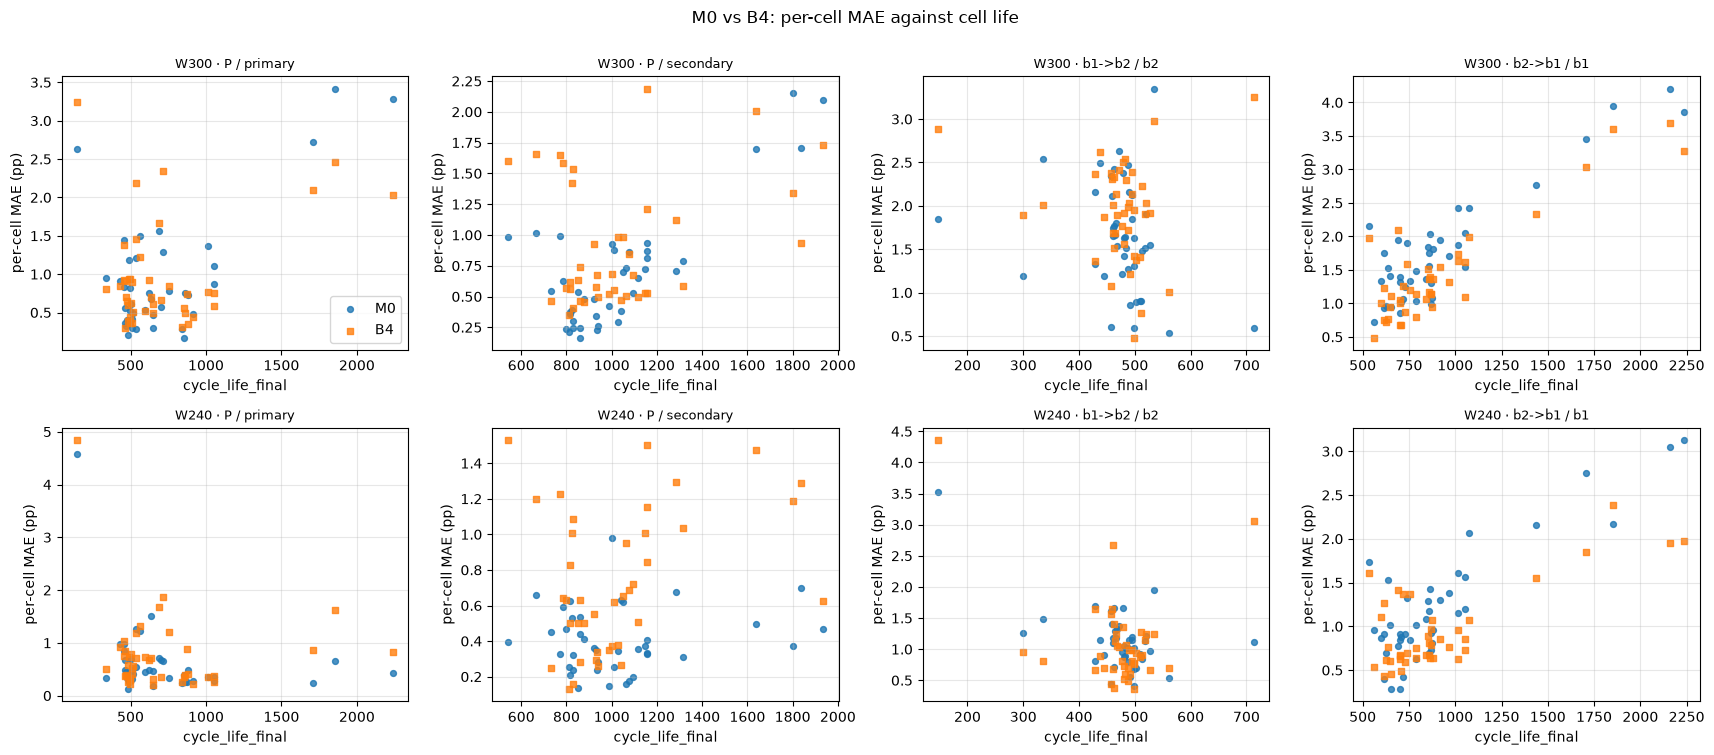

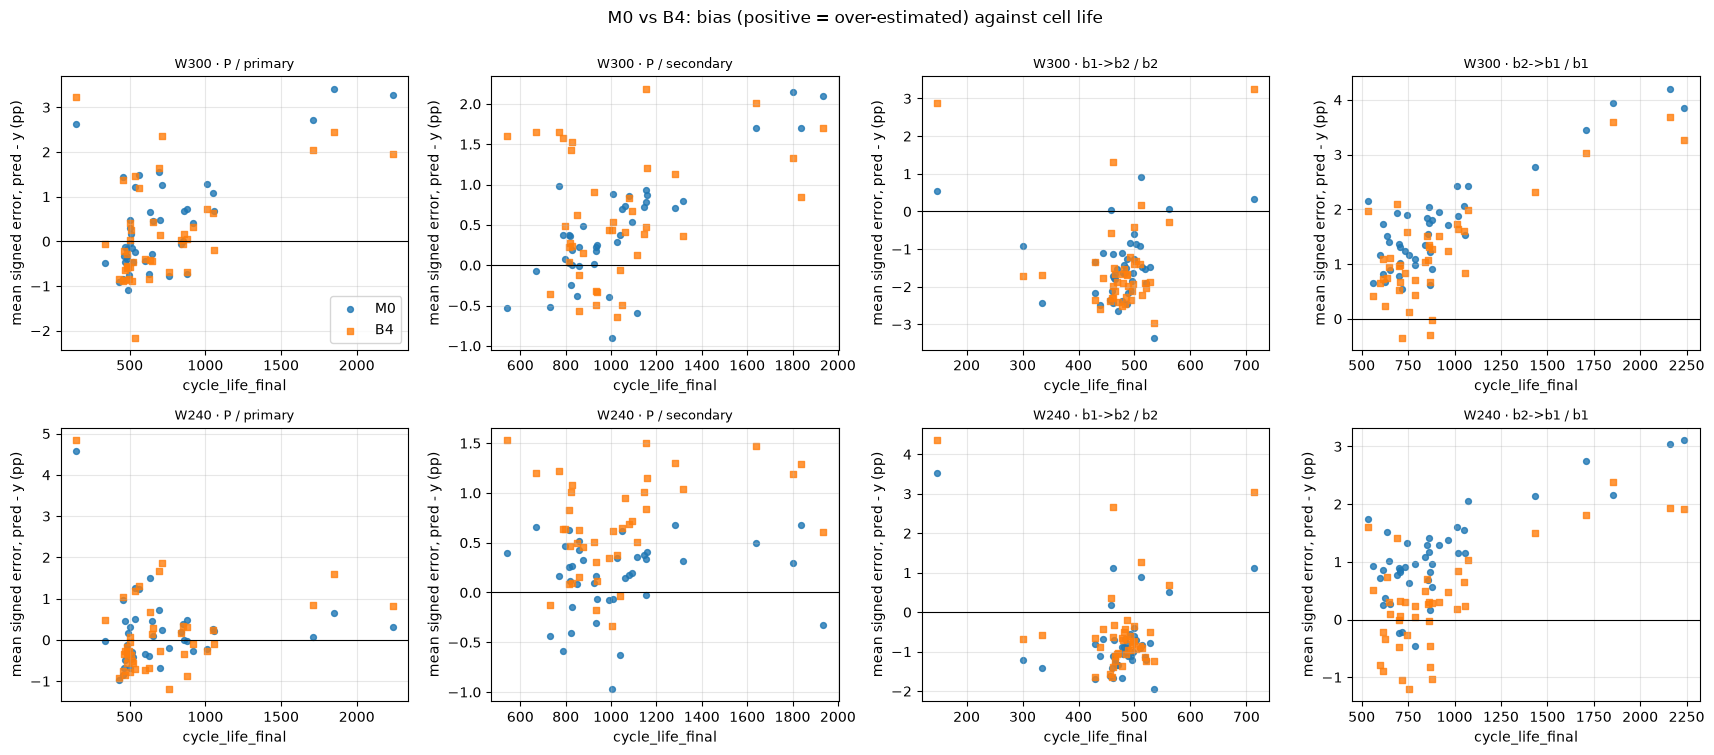

[PASS] [end] sha256 frozen_config - frozen_config.json: expected 78b571c7526551c7..., got 78b571c7526551c7...
[PASS] [end] sha256 soh_deep_v4 - soh_deep_v4.py: expected 2be9ce5ded197b16..., got 2be9ce5ded197b16...
[PASS] [end] sha256 soh_deep_v3 - soh_deep_v3.py: expected 9c022dd391193de9..., got 9c022dd391193de9...
[PASS] [end] sha256 preregistration - preregistration.json: expected 11f9741387cb001e..., got 11f9741387cb001e...
[PASS] [end] sha256 batch3_verdict - batch3_verdict.json: expected 57a054bdf25243d3..., got 57a054bdf25243d3...
[PASS] [end] sha256 monitor_config - monitor_config.json: expected 638b6c3a6ad31c69..., got 638b6c3a6ad31c69...
[PASS] [end] sha256 monitor_config_addendum - monitor_config_addendum.json: expected d842e5f4c3186889..., got d842e5f4c3186889...
[PASS] predictions file unchanged since it was hashed - 0669a1d338220f08...
[PASS] no batch-3 label read before predictions_written (label log) - 1 batch-3 label read(s), all after the predictions_written entry
[PA

In [9]:
# S7 · CSVs, figures, final guards, report, verification report, log "done"
SCORES.to_csv(W(OUT / "phase7c_scores.csv"), index=False)
PAIRED.to_csv(W(OUT / "phase7c_paired.csv"), index=False)
TERT.to_csv(W(OUT / "phase7c_by_life_tertile.csv"), index=False)
BYCELL.to_csv(W(OUT / "phase7c_by_cell.csv"), index=False)
TWINT.to_csv(W(OUT / "phase7c_policy_twin.csv"), index=False)
CTX.to_csv(W(OUT / "phase7c_context.csv"), index=False)
EXPR.to_csv(W(OUT / "phase7c_expectations.csv"), index=False)
H8.to_csv(W(OUT / "phase7c_h8_detail.csv"), index=False)

SETS = [(p, t) for p, t, _ in TEST_SETS]
for kind, fn, ylab, ttl in [("mae", "fig_percell_mae_vs_life_M0_vs_B4.png", "per-cell MAE (pp)", "per-cell MAE"), ("bias", "fig_bias_vs_life_M0_vs_B4.png", "mean signed error, pred - y (pp)", "bias (positive = over-estimated)")]:
    fig, axs = plt.subplots(2, len(SETS), figsize=(4.3 * len(SETS), 7.5), squeeze=False)
    for i, w in enumerate(WINDOWS):
        for j, (prot, ts) in enumerate(SETS):
            ax = axs[i, j]; uc = TS_CELLS[(prot, ts)]; lf = [LIFE[c] for c in uc]
            for m, mk in (("M0", "o"), ("B4", "s")):
                v = PCELL[(prot, ts, w, m)][0 if kind == "mae" else 1]
                ax.scatter(lf, v, marker=mk, s=18, alpha=.8, label=m)
            if kind == "bias": ax.axhline(0, color="k", lw=.8)
            ax.set_title(f"{w} · {prot} / {ts}", fontsize=9); ax.set_xlabel("cycle_life_final"); ax.set_ylabel(ylab); ax.grid(alpha=.3)
            if i == 0 and j == 0: ax.legend()
    fig.suptitle(f"M0 vs B4: {ttl} against cell life", y=1.0); fig.tight_layout(); fig.savefig(W(OUT / "figures" / fn), dpi=150); plt.show()

HASHES_END = verify_frozen("end")
check("predictions file unchanged since it was hashed", sha256_file(PRED_PATH) == PRED_SHA, PRED_SHA[:16] + "...")
check("no batch-3 label read before predictions_written (label log)", [r for r in LABEL_LOG if r["b3_label"]] and min(r["t"] for r in LABEL_LOG if r["b3_label"]) > 0 and log_has("predictions_written"),
      f"{sum(r['b3_label'] for r in LABEL_LOG)} batch-3 label read(s), all after the predictions_written entry")
check("nothing selected on these results", True, "no model, window, threshold or setting is chosen from phase 7c; expectations were registered before scoring")
n_lines, bad = verify_chain()
check("log hash chain intact", not bad, f"{n_lines} entries, broken links at {bad}")
RUNTIME_MIN = (time.time() - T0) / 60
check("runtime under 25 minutes", RUNTIME_MIN < 25 or SMOKE, f"{RUNTIME_MIN:.1f} min", warn_only=True)

arts = [dict(path=str(p.relative_to(ROOT)), size_kb=round(p.stat().st_size / 1024, 1)) for p in sorted(OUT.rglob("*")) if p.is_file() and "cache" not in p.relative_to(OUT).parts]
_c = [p for p in CACHE.rglob("*") if p.is_file()] if CACHE.exists() else []
arts.append(dict(path=str(CACHE.relative_to(ROOT)) + f" ({len(_c)} files)", size_kb=round(sum(p.stat().st_size for p in _c) / 1024, 1)))
ART = pd.DataFrame(arts)
EXTRA.update(dict(hashes_start=HASHES_START, hashes_end=HASHES_END, predictions_sha256=PRED_SHA, expectations_sha256=EXP_SHA, runtime_min=round(RUNTIME_MIN, 2),
                  device=_name, torch=torch.__version__, label_reads=LABEL_LOG, life_tertile_cuts=[float(c) for c in CUTS],
                  expectations={r.id: dict(expected=r.expected, observed=r.observed, consistent=r.consistent) for _, r in EXPR.iterrows()}, artifacts=arts))
_nf = sum(c["status"] == "FAIL" for c in CHECKS)
tail = ["ARTIFACTS", "-" * 78, ART.to_string(index=False), "", f"RUNTIME {RUNTIME_MIN:.1f} min | PASS {sum(c['status'] == 'PASS' for c in CHECKS)} | WARN {sum(c['status'] == 'WARN' for c in CHECKS)} | FAIL {_nf}"]
rep = dict(created_utc=now_utc(), smoke=SMOKE, failed=None, checks=CHECKS, extra=EXTRA, elapsed_s=round(time.time() - T0, 1))
write_json(VER_PATH, rep)
write_text(REPORT_PATH, report_text(tail))
log_append("done", report_sha256=sha256_file(REPORT_PATH), verification_report_sha256=sha256_file(VER_PATH), predictions_sha256=PRED_SHA, runtime_min=round(RUNTIME_MIN, 2), n_fail=_nf, smoke=SMOKE)
print(ART.to_string(index=False))
print("\n" + tail[-1])
keep_awake(False)
